# Experiment 02 — Eight Queens Problem

**Name:** Naman Chanana  
**SAP ID:** 500119485  
**Roll No.:** R2142230993  
**Batch:** 2 — AI & ML  

## Aim
Solve the **N-Queens / Eight Queens problem** using generate-and-test and backtracking approaches, compare their performance, study board symmetries, and visualize valid solutions.


In [1]:
import itertools
import json
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

Path("figs").mkdir(exist_ok=True)

print("Environment ready.")


Environment ready.


## 1. Generate-and-Test

A board is represented as a tuple where the value at each column gives the row occupied by its queen.

Using a permutation automatically guarantees that no two queens share a row. We then test whether any two queens share a diagonal.


In [2]:
def is_valid(board):
    n = len(board)
    for c1 in range(n):
        for c2 in range(c1 + 1, n):
            if abs(board[c1] - board[c2]) == abs(c1 - c2):
                return False
    return True

def generate_and_test(n):
    solutions = []
    for board in itertools.permutations(range(n)):
        if is_valid(board):
            solutions.append(board)
    return solutions

start = time.perf_counter()
generate_solutions = generate_and_test(8)
generate_time_8 = time.perf_counter() - start

print("Generate-and-test solutions for 8 queens:", len(generate_solutions))
print(f"Runtime: {generate_time_8:.4f} s")
print("First solution:", generate_solutions[0])


Generate-and-test solutions for 8 queens: 92
Runtime: 0.0500 s
First solution: (0, 4, 7, 5, 2, 6, 1, 3)


## 2. Backtracking with Pruning

Backtracking places queens column by column and immediately rejects partial boards that already violate row or diagonal constraints.


In [3]:
def solve_backtracking(n):
    solutions = []
    board = [-1] * n

    def place(col, used_rows, diag1, diag2):
        if col == n:
            solutions.append(tuple(board))
            return

        for row in range(n):
            d1 = row - col
            d2 = row + col

            if row in used_rows or d1 in diag1 or d2 in diag2:
                continue

            board[col] = row
            place(
                col + 1,
                used_rows | {row},
                diag1 | {d1},
                diag2 | {d2},
            )
            board[col] = -1

    place(0, set(), set(), set())
    return solutions

start = time.perf_counter()
backtracking_solutions = solve_backtracking(8)
backtracking_time_8 = time.perf_counter() - start

print("Backtracking solutions for 8 queens:", len(backtracking_solutions))
print(f"Runtime: {backtracking_time_8:.6f} s")
print("First solution:", backtracking_solutions[0])

assert set(generate_solutions) == set(backtracking_solutions)
assert len(backtracking_solutions) == 92

print("\nVerification: both methods found the same 92 solutions.")


Backtracking solutions for 8 queens: 92
Runtime: 0.011346 s
First solution: (0, 4, 7, 5, 2, 6, 1, 3)

Verification: both methods found the same 92 solutions.


## 3. Visualize a Valid Eight-Queens Solution


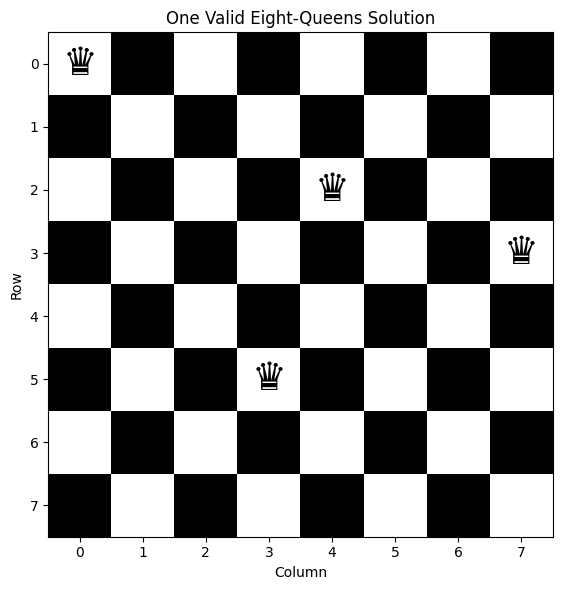

In [4]:
def plot_board(board, filename=None):
    n = len(board)
    chessboard = np.indices((n, n)).sum(axis=0) % 2

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(chessboard, cmap="binary", vmin=0, vmax=1)

    for col, row in enumerate(board):
        ax.text(
            col, row, "♛",
            ha="center", va="center",
            fontsize=28,
        )

    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    ax.set_title("One Valid Eight-Queens Solution")
    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)

    plt.tight_layout()
    if filename:
        plt.savefig(filename, dpi=160, bbox_inches="tight")
    plt.show()

plot_board(backtracking_solutions[0], "figs/fig2_1_board.png")


## 4. Runtime Comparison

Generate-and-test explores every permutation (`n!` possibilities), while backtracking prunes invalid partial states early.


In [5]:
sizes = list(range(4, 11))
generate_times = []
backtracking_times = []
solution_counts = []

for n in sizes:
    start = time.perf_counter()
    sol_gen = generate_and_test(n)
    t_gen = time.perf_counter() - start

    start = time.perf_counter()
    sol_bt = solve_backtracking(n)
    t_bt = time.perf_counter() - start

    assert set(sol_gen) == set(sol_bt)

    generate_times.append(t_gen)
    backtracking_times.append(t_bt)
    solution_counts.append(len(sol_bt))

    print(
        f"n={n:2d} | solutions={len(sol_bt):4d} | "
        f"generate-test={t_gen:.6f}s | backtracking={t_bt:.6f}s"
    )


n= 4 | solutions=   2 | generate-test=0.000032s | backtracking=0.000032s
n= 5 | solutions=  10 | generate-test=0.000121s | backtracking=0.000092s
n= 6 | solutions=   4 | generate-test=0.000590s | backtracking=0.000257s
n= 7 | solutions=  40 | generate-test=0.006700s | backtracking=0.001277s
n= 8 | solutions=  92 | generate-test=0.043930s | backtracking=0.003949s
n= 9 | solutions= 352 | generate-test=0.423955s | backtracking=0.016760s
n=10 | solutions= 724 | generate-test=4.694226s | backtracking=0.139486s


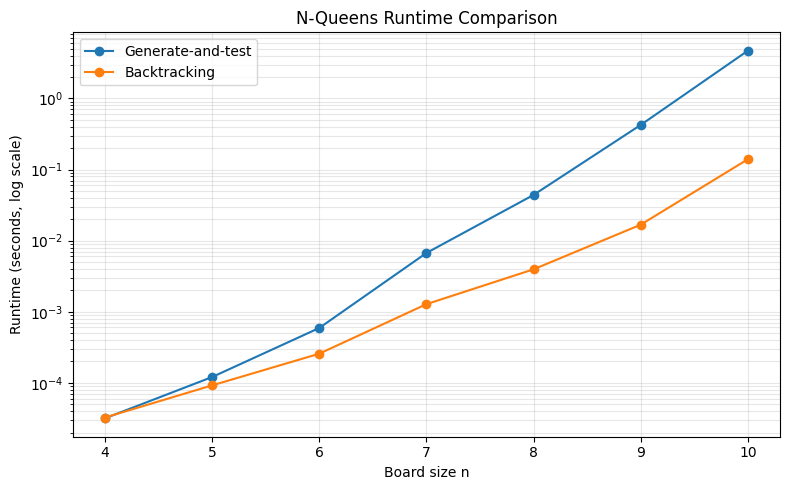

In [6]:
plt.figure(figsize=(8, 5))
plt.semilogy(sizes, generate_times, "o-", label="Generate-and-test")
plt.semilogy(sizes, backtracking_times, "o-", label="Backtracking")
plt.xlabel("Board size n")
plt.ylabel("Runtime (seconds, log scale)")
plt.title("N-Queens Runtime Comparison")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("figs/fig2_2_runtime.png", dpi=160, bbox_inches="tight")
plt.show()


## 5. Fundamental Solutions Under Symmetry

Many of the 92 Eight-Queens solutions are rotations or reflections of one another. We group symmetric boards together to count the number of fundamentally different solutions.


In [7]:
def board_to_points(board):
    return {(c, r) for c, r in enumerate(board)}

def points_to_board(points, n):
    board = [-1] * n
    for c, r in points:
        board[c] = r
    return tuple(board)

def rotate90(points, n):
    return {(n - 1 - r, c) for c, r in points}

def reflect(points, n):
    return {(n - 1 - c, r) for c, r in points}

def symmetries(board):
    n = len(board)
    p = board_to_points(board)
    variants = set()

    for _ in range(4):
        variants.add(points_to_board(p, n))
        variants.add(points_to_board(reflect(p, n), n))
        p = rotate90(p, n)

    return variants

canonical = {min(symmetries(board)) for board in backtracking_solutions}

print("Total Eight-Queens solutions:", len(backtracking_solutions))
print("Fundamental solutions under rotations/reflections:", len(canonical))

assert len(canonical) == 12


Total Eight-Queens solutions: 92
Fundamental solutions under rotations/reflections: 12


## 6. Demonstrating a Common Diagonal-Check Bug

The following deliberately incorrect validity test checks only one diagonal direction. It therefore accepts invalid boards and demonstrates why both diagonal directions must be checked.


In [8]:
def buggy_is_valid(board):
    n = len(board)
    for c1 in range(n):
        for c2 in range(c1 + 1, n):
            # Incorrect: checks only one signed diagonal relation.
            if board[c1] - board[c2] == c1 - c2:
                return False
    return True

buggy_solutions = [
    board for board in itertools.permutations(range(8))
    if buggy_is_valid(board)
]

invalid_examples = [b for b in buggy_solutions if not is_valid(b)]

print("Solutions accepted by buggy check:", len(buggy_solutions))
print("Actually valid solutions:", len(backtracking_solutions))
print("Invalid boards incorrectly accepted:", len(invalid_examples))
print("Example incorrectly accepted board:", invalid_examples[0])


Solutions accepted by buggy check: 2113
Actually valid solutions: 92
Invalid boards incorrectly accepted: 2021
Example incorrectly accepted board: (0, 2, 5, 7, 6, 3, 1, 4)


## 7. Save Results


In [9]:
results = {
    "student": {
        "name": "Naman Chanana",
        "sap_id": "500119485",
        "roll_no": "R2142230993",
        "batch": "2 - AI & ML",
    },
    "eight_queens": {
        "total_solutions": len(backtracking_solutions),
        "fundamental_solutions": len(canonical),
        "generate_and_test_runtime_seconds": generate_time_8,
        "backtracking_runtime_seconds": backtracking_time_8,
        "first_solution": list(backtracking_solutions[0]),
    },
    "runtime_comparison": [
        {
            "n": n,
            "solutions": count,
            "generate_and_test_seconds": tg,
            "backtracking_seconds": tb,
        }
        for n, count, tg, tb in zip(
            sizes, solution_counts, generate_times, backtracking_times
        )
    ],
    "bug_demo": {
        "buggy_solution_count": len(buggy_solutions),
        "invalid_accepted_count": len(invalid_examples),
    },
}

with open("results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)

print("Saved results.json and 2 figures in figs/")


Saved results.json and 2 figures in figs/


## Conclusion

The Eight Queens problem was solved using both generate-and-test and backtracking.

- Both correct methods produce **92 solutions** for the standard 8×8 board.
- Symmetry reduction gives **12 fundamental solutions**.
- Backtracking is more efficient because it prunes invalid partial configurations before constructing complete boards.
- The deliberately buggy diagonal test demonstrates how an incomplete constraint check can accept invalid solutions.
